# Семинар 1. Когнитивная архитектура как инженерная система

**Курс:** Когнитивные архитектуры  
**Направление:** 09.04.03 Прикладная информатика, магистратура  


## Цель семинара

На первом семинаре мы не реализуем полноценную ACT-R, Soar или LLM-agent систему.  
Наша задача — научиться описывать когнитивную архитектуру **инженерно**:

- выделять состояние агента;
- определять наблюдения и действия;
- описывать переходы между режимами;
- строить простейший замкнутый цикл;
- обрабатывать отказы;
- вводить safety layer;
- измерять качество работы;
- связать когнитивный цикл с понятиями теории автоматического управления.

## Правило работы с ноутбуком

В заданиях редактируйте **только** код между строками:

```python
# ===== BEGIN STUDENT CODE =====

# ===== END STUDENT CODE =====
```

Сигнатуры функций, входные данные, `return`, тесты и служебный код уже подготовлены.

## План занятия

| Время | Блок |
|---:|---|
| 0–10 мин | Подготовка среды и инженерный словарь |
| 10–25 мин | Сравнение исполняемых архитектур |
| 25–50 мин | Когнитивный цикл как конечный автомат |
| 50–65 мин | Agent loop и журналирование |
| 65–75 мин | Safety filter и обработка отказов |
| 75–85 мин | Closed-loop эксперимент |
| 85–90 мин | Идея семестрового проекта и рефлексия |

# 0. Подготовка среды

Ноутбук использует стандартную библиотеку Python, `pandas` и, опционально, `matplotlib`.
Все обязательные задания можно выполнить локально без LLM API.

In [1]:
from dataclasses import dataclass, field, asdict
from enum import Enum
from typing import Dict, List, Optional, Any, Tuple
from collections import Counter
import copy
import random

import pandas as pd

try:
    import matplotlib.pyplot as plt
    HAS_MATPLOTLIB = True
except Exception:
    HAS_MATPLOTLIB = False

pd.set_option("display.max_colwidth", 120)

print("Среда готова")

Среда готова


# 1. Архитектуры, пригодные для учебного эксперимента

В курсе рассматриваются прежде всего архитектуры и agent runtimes, которые можно реально запускать, исследовать или подключать через открытый код/API.

Стартовая таблица содержит:

- ACT-R / pyactr;
- Soar;
- STRL;
- NengoSPA;
- OpenCog Hyperon / MeTTa;
- LangGraph;
- Microsoft AutoGen;
- OpenAI Agents SDK.

Здесь нас интересует не история систем, а их **инженерная форма**:
какое у них состояние, что считается действием, как осуществляется переход и как подключается внешняя среда.

In [2]:
architectures = [
    {
        "name": "ACT-R / pyactr",
        "family": "symbolic / cognitive",
        "execution": "local",
        "code_or_api": "official ACT-R source + pyactr Python package",
        "state_unit": "buffers + declarative memory",
        "action_unit": "production rule firing",
    },
    {
        "name": "Soar",
        "family": "symbolic / problem-space",
        "execution": "local",
        "code_or_api": "public source + SML API + Python bindings",
        "state_unit": "working memory + input link",
        "action_unit": "operator selection + output link",
    },
    {
        "name": "STRL",
        "family": "hierarchical / cognitive control",
        "execution": "local",
        "code_or_api": "open research code / planning components",
        "state_unit": "strategic + tactical + reactive representations",
        "action_unit": "hierarchical plan / control action",
    },
    {
        "name": "NengoSPA",
        "family": "neural-symbolic / cognitive",
        "execution": "local",
        "code_or_api": "Python package + public examples",
        "state_unit": "semantic pointers / memories",
        "action_unit": "action selection",
    },
    {
        "name": "OpenCog Hyperon / MeTTa",
        "family": "symbolic / neural-symbolic",
        "execution": "local",
        "code_or_api": "public repository + Python bindings",
        "state_unit": "knowledge spaces / atoms",
        "action_unit": "rule / expression execution",
    },
    {
        "name": "LangGraph",
        "family": "LLM agent runtime",
        "execution": "local or API-backed",
        "code_or_api": "open-source Python framework",
        "state_unit": "explicit graph state",
        "action_unit": "node / tool transition",
    },
    {
        "name": "Microsoft AutoGen",
        "family": "LLM multi-agent runtime",
        "execution": "local or API-backed",
        "code_or_api": "open-source AgentChat/Core",
        "state_unit": "agent messages + runtime state",
        "action_unit": "message / tool / event",
    },
    {
        "name": "OpenAI Agents SDK",
        "family": "LLM agent runtime",
        "execution": "API-backed or provider-adapted",
        "code_or_api": "open-source SDK",
        "state_unit": "run context + messages + tool state",
        "action_unit": "tool call / handoff / agent output",
    },
]

arch_df = pd.DataFrame(architectures)
arch_df

,name,family,execution,code_or_api,state_unit,action_unit
0,ACT-R / pyactr,symbolic / cognitive,local,official ACT-R source + pyactr Python package,buffers + declarative memory,production rule firing
1,Soar,symbolic / problem-space,local,public source + SML API + Python bindings,working memory + input link,operator selection + output link
2,STRL,hierarchical / cognitive control,local,open research code / planning components,strategic + tactical + reactive representations,hierarchical plan / control action
3,NengoSPA,neural-symbolic / cognitive,local,Python package + public examples,semantic pointers / memories,action selection
4,OpenCog Hyperon / MeTTa,symbolic / neural-symbolic,local,public repository + Python bindings,knowledge spaces / atoms,rule / expression execution
5,LangGraph,LLM agent runtime,local or API-backed,open-source Python framework,explicit graph state,node / tool transition
6,Microsoft AutoGen,LLM multi-agent runtime,local or API-backed,open-source AgentChat/Core,agent messages + runtime state,message / tool / event
7,OpenAI Agents SDK,LLM agent runtime,API-backed or provider-adapted,open-source SDK,run context + messages + tool state,tool call / handoff / agent output


## Задание 1. Добавьте инженерные критерии

Добавьте для каждой архитектуры:

- `has_explicit_state` — есть ли явно представимое состояние;
- `has_action_interface` — есть ли явный интерфейс действия;
- `control_analogy` — аналогия с ТАУ: `supervisor`, `controller`, `planner`, `observer`, `runtime` или их комбинация;
- `seminar_risk` — `low`, `medium`, `high`;
- `project_recommendation` — кратко, для какого проекта её стоит использовать.

**Ожидаемый результат:** таблица должна быть пригодна для выбора стека семестрового проекта.

In [3]:
# Создаем новые столбцы заранее.
arch_df["has_explicit_state"] = None
arch_df["has_action_interface"] = None
arch_df["control_analogy"] = None
arch_df["seminar_risk"] = None
arch_df["project_recommendation"] = None

# ===== BEGIN STUDENT CODE =====

# у всех архитектур состояние и действия описаны явно (см. state_unit и action_unit)
arch_df["has_explicit_state"] = True
arch_df["has_action_interface"] = True

control_analogy_map = {
    "ACT-R / pyactr": "controller",
    "Soar": "planner",
    "STRL": "supervisor + planner",
    "NengoSPA": "controller + observer",
    "OpenCog Hyperon / MeTTa": "runtime",
    "LangGraph": "controller",
    "Microsoft AutoGen": "supervisor",
    "OpenAI Agents SDK": "runtime",
}

risk_map = {
    "ACT-R / pyactr": "high",
    "Soar": "high",
    "STRL": "high",
    "NengoSPA": "medium",
    "OpenCog Hyperon / MeTTa": "high",
    "LangGraph": "low",
    "Microsoft AutoGen": "medium",
    "OpenAI Agents SDK": "medium",
}

recommendation_map = {
    "ACT-R / pyactr": "модели памяти и внимания человека",
    "Soar": "задачи планирования и поиска решения",
    "STRL": "управление роботом на трёх уровнях: стратегия, тактика, реакция",
    "NengoSPA": "проекты, где нужны нейронные сети и символы вместе",
    "OpenCog Hyperon / MeTTa": "исследование знаний; риск высокий, инструмент сложный",
    "LangGraph": "хороший выбор для моего проекта: состояние хранится в графе, риск низкий",
    "Microsoft AutoGen": "проекты с несколькими агентами",
    "OpenAI Agents SDK": "быстрые проекты с вызовом инструментов; состояние видно хуже",
}

arch_df["control_analogy"] = arch_df["name"].map(control_analogy_map)
arch_df["seminar_risk"] = arch_df["name"].map(risk_map)
arch_df["project_recommendation"] = arch_df["name"].map(recommendation_map)

# ===== END STUDENT CODE =====

arch_df

,name,family,execution,code_or_api,state_unit,action_unit,has_explicit_state,has_action_interface,control_analogy,seminar_risk,project_recommendation
0,ACT-R / pyactr,symbolic / cognitive,local,official ACT-R source + pyactr Python package,buffers + declarative memory,production rule firing,True,True,controller,high,модели памяти и внимания человека
1,Soar,symbolic / problem-space,local,public source + SML API + Python bindings,working memory + input link,operator selection + output link,True,True,planner,high,задачи планирования и поиска решения
2,STRL,hierarchical / cognitive control,local,open research code / planning components,strategic + tactical + reactive representations,hierarchical plan / control action,True,True,supervisor + planner,high,"управление роботом на трёх уровнях: стратегия, тактика, реакция"
3,NengoSPA,neural-symbolic / cognitive,local,Python package + public examples,semantic pointers / memories,action selection,True,True,controller + observer,medium,"проекты, где нужны нейронные сети и символы вместе"
4,OpenCog Hyperon / MeTTa,symbolic / neural-symbolic,local,public repository + Python bindings,knowledge spaces / atoms,rule / expression execution,True,True,runtime,high,"исследование знаний; риск высокий, инструмент сложный"
5,LangGraph,LLM agent runtime,local or API-backed,open-source Python framework,explicit graph state,node / tool transition,True,True,controller,low,"хороший выбор для моего проекта: состояние хранится в графе, риск низкий"
6,Microsoft AutoGen,LLM multi-agent runtime,local or API-backed,open-source AgentChat/Core,agent messages + runtime state,message / tool / event,True,True,supervisor,medium,проекты с несколькими агентами
7,OpenAI Agents SDK,LLM agent runtime,API-backed or provider-adapted,open-source SDK,run context + messages + tool state,tool call / handoff / agent output,True,True,runtime,medium,быстрые проекты с вызовом инструментов; состояние видно хуже


### Самопроверка задания 1

In [4]:
def check_architecture_table(df: pd.DataFrame) -> None:
    required = [
        "has_explicit_state",
        "has_action_interface",
        "control_analogy",
        "seminar_risk",
        "project_recommendation",
    ]
    for col in required:
        assert col in df.columns, f"Нет столбца {col}"
        assert df[col].notna().all(), f"Не все значения заполнены в {col}"

    assert df["seminar_risk"].isin(["low", "medium", "high"]).all(), (
        "seminar_risk должен содержать только low / medium / high"
    )

    print("Задание 1: базовые проверки пройдены")

check_architecture_table(arch_df)

Задание 1: базовые проверки пройдены


# 2. Когнитивный цикл как конечный автомат

Опишем агента через набор режимов.

Это важный переход от фразы «агент думает и действует» к формальной модели:

\[
q_{t+1} = F(q_t, o_t),
\]

где:

- \(q_t\) — дискретный режим;
- \(o_t\) — наблюдение;
- \(F\) — функция перехода.

In [5]:
class Mode(Enum):
    IDLE = "IDLE"
    PERCEIVE = "PERCEIVE"
    UPDATE_STATE = "UPDATE_STATE"
    PLAN = "PLAN"
    ACT = "ACT"
    EVALUATE = "EVALUATE"
    RECOVERY = "RECOVERY"
    DONE = "DONE"

## Состояние агента

Внутреннее состояние сделаем явным.

`AgentState` хранит:

- текущий режим;
- цель;
- память;
- историю действий;
- ошибки;
- текущую оценку успешности;
- номер шага.

In [6]:
@dataclass
class AgentState:
    mode: Mode = Mode.IDLE
    goal: Optional[str] = None
    memory: Dict[str, Any] = field(default_factory=dict)
    action_history: List[str] = field(default_factory=list)
    error_count: int = 0
    last_error: Optional[str] = None
    success_score: float = 0.0
    step: int = 0

state = AgentState()
state

AgentState(mode=<Mode.IDLE: 'IDLE'>, goal=None, memory={}, action_history=[], error_count=0, last_error=None, success_score=0.0, step=0)

## Задание 2. Реализуйте функцию перехода

Правила автомата:

1. `IDLE` + непустая цель → `PERCEIVE`;
2. `PERCEIVE` → `UPDATE_STATE`;
3. `UPDATE_STATE` → `PLAN`;
4. `PLAN` → `ACT`;
5. `ACT`:
   - `tool_error=True` → `RECOVERY`;
   - иначе → `EVALUATE`;
6. `EVALUATE`:
   - `success_score >= 1.0` → `DONE`;
   - иначе → `PERCEIVE`;
7. `RECOVERY`:
   - ошибок меньше 3 → `PLAN`;
   - иначе → `DONE`.

Функция не должна изменять исходный объект `state` по ссылке.

In [7]:
def transition(state: AgentState, observation: Dict[str, Any]) -> AgentState:
    next_state = copy.deepcopy(state)
    next_state.step += 1

    # ===== BEGIN STUDENT CODE =====

    # смотрим на текущий режим и выбираем следующий
    if next_state.mode == Mode.IDLE:
        if next_state.goal:
            next_state.mode = Mode.PERCEIVE

    elif next_state.mode == Mode.PERCEIVE:
        next_state.mode = Mode.UPDATE_STATE

    elif next_state.mode == Mode.UPDATE_STATE:
        next_state.mode = Mode.PLAN

    elif next_state.mode == Mode.PLAN:
        next_state.mode = Mode.ACT

    elif next_state.mode == Mode.ACT:
        if observation.get("tool_error", False):
            # ошибка инструмента: считаем её и идём в RECOVERY
            next_state.mode = Mode.RECOVERY
            next_state.error_count += 1
            next_state.last_error = observation.get("error_message")
        else:
            next_state.mode = Mode.EVALUATE

    elif next_state.mode == Mode.EVALUATE:
        if next_state.success_score >= 1.0:
            next_state.mode = Mode.DONE
        else:
            next_state.mode = Mode.PERCEIVE

    elif next_state.mode == Mode.RECOVERY:
        # после трёх ошибок агент останавливается
        if next_state.error_count < 3:
            next_state.mode = Mode.PLAN
        else:
            next_state.mode = Mode.DONE

    # ===== END STUDENT CODE =====

    return next_state

### Самопроверка задания 2

In [8]:
def check_transition() -> None:
    s = AgentState(mode=Mode.IDLE, goal="demo")
    s2 = transition(s, {})
    assert s.mode == Mode.IDLE, "Исходный state не должен меняться"
    assert s2.mode == Mode.PERCEIVE, "IDLE с целью должен перейти в PERCEIVE"

    s = AgentState(mode=Mode.ACT, goal="demo")
    s2 = transition(s, {"tool_error": False})
    assert s2.mode == Mode.EVALUATE, "ACT без ошибки -> EVALUATE"

    s = AgentState(mode=Mode.ACT, goal="demo")
    s2 = transition(s, {"tool_error": True, "error_message": "timeout"})
    assert s2.mode == Mode.RECOVERY, "ACT с ошибкой -> RECOVERY"
    assert s2.error_count == 1, "Счетчик ошибок должен увеличиться"

    s = AgentState(mode=Mode.EVALUATE, goal="demo", success_score=1.0)
    s2 = transition(s, {})
    assert s2.mode == Mode.DONE, "При success_score >= 1.0 агент должен завершиться"

    print("Задание 2: базовые проверки пройдены")

check_transition()

Задание 2: базовые проверки пройдены


# 3. Функции когнитивного цикла

Теперь отделим:

- **восприятие**;
- **планирование**;
- **действие**;
- **оценку результата**.

Это позволит позже заменить любой блок:
например, rule-based planner — на LLM planner, а простой `act()` — на реальный tool/API.

## Задание 3. Реализуйте `perceive`

Требования:

- возвращается словарь;
- всегда присутствуют `new_information` и `tool_error`;
- если в `state.memory` есть `force_tool_error=True`, вернуть ошибку;
- в обычном режиме `new_information=True`.

In [9]:
def perceive(state: AgentState) -> Dict[str, Any]:
    observation = {
        "new_information": False,
        "tool_error": False,
        "error_message": None,
    }

    # ===== BEGIN STUDENT CODE =====

    if state.memory.get("force_tool_error", False):
        # ошибка датчика
        observation["tool_error"] = True
        observation["error_message"] = "tool error"
    else:
        observation["new_information"] = True

    # ===== END STUDENT CODE =====

    return observation

## Задание 4. Реализуйте `plan`

Требования:

- если цель не задана → `no_op`;
- если в памяти отсутствует `belief_updated` → `request_observation`;
- иначе → `execute_tool`.

In [10]:
def plan(state: AgentState) -> str:
    action = "no_op"

    # ===== BEGIN STUDENT CODE =====

    if not state.goal:
        action = "no_op"
    elif not state.memory.get("belief_updated", False):
        action = "request_observation"
    else:
        action = "execute_tool"

    # ===== END STUDENT CODE =====

    return action

## Задание 5. Реализуйте `act`

В этой лабораторной работе инструмент искусственный.

Требования:

- `no_op` → отсутствие прогресса;
- `request_observation` → небольшой прогресс;
- `execute_tool` → прогресс `0.55`;
- для `execute_tool` с вероятностью `error_probability` происходит ошибка.

Используйте переданный генератор `rng`, а не глобальный `random`.

In [11]:
def act(
    action: str,
    rng: random.Random,
    error_probability: float = 0.20
) -> Dict[str, Any]:

    result = {
        "action": action,
        "ok": True,
        "progress": 0.0,
        "tool_error": False,
        "error_message": None,
    }

    # ===== BEGIN STUDENT CODE =====

    if action == "no_op":
        result["progress"] = 0.0

    elif action == "request_observation":
        result["progress"] = 0.15

    elif action == "execute_tool":
        # rng даёт случайное число от 0 до 1
        if rng.random() < error_probability:
            result["ok"] = False
            result["tool_error"] = True
            result["error_message"] = "tool error"
            result["progress"] = 0.0
        else:
            result["progress"] = 0.55

    else:
        # неизвестное действие
        result["ok"] = False
        result["error_message"] = "unknown action"

    # ===== END STUDENT CODE =====

    return result

## Задание 6. Реализуйте `evaluate`

Требования:

- при успешном действии увеличивать `success_score` на `result["progress"]`;
- ограничить `success_score` сверху значением `1.0`;
- сохранить последний результат в `memory["last_result"]`;
- при неуспешном действии score не увеличивать.

In [12]:
def evaluate(state: AgentState, result: Dict[str, Any]) -> AgentState:
    next_state = copy.deepcopy(state)

    # ===== BEGIN STUDENT CODE =====

    # прогресс добавляем только если действие прошло успешно
    if result.get("ok", False):
        next_state.success_score = min(
            1.0,
            next_state.success_score + result.get("progress", 0.0)
        )

    next_state.memory["last_result"] = result

    # ===== END STUDENT CODE =====

    return next_state

### Самопроверка заданий 3–6

In [13]:
def check_cycle_functions() -> None:
    s = AgentState(goal="demo")
    obs = perceive(s)
    assert isinstance(obs, dict)
    assert "new_information" in obs
    assert "tool_error" in obs

    assert plan(AgentState(goal=None)) == "no_op"

    s2 = AgentState(goal="demo", memory={})
    assert plan(s2) == "request_observation"

    s3 = AgentState(goal="demo", memory={"belief_updated": True})
    assert plan(s3) == "execute_tool"

    rng = random.Random(1)
    r = act("no_op", rng)
    assert r["progress"] == 0.0

    s4 = AgentState(success_score=0.7)
    s5 = evaluate(s4, {"ok": True, "progress": 0.5})
    assert 0.99 <= s5.success_score <= 1.0

    print("Задания 3–6: базовые проверки пройдены")

check_cycle_functions()

Задания 3–6: базовые проверки пройдены


# 4. Сборка agent loop

Теперь объединим компоненты в один цикл.

В терминах ТАУ это уже замкнутая структура:

**цель → решение → действие → среда → наблюдение → обновление состояния → новое решение**

В терминах agentic systems — это минимальный **agent runtime loop**.

## Задание 7. Реализуйте `run_agent`

Функция должна:

1. создать `AgentState`;
2. выполнять цикл не более `max_steps`;
3. вызывать нужную функцию в зависимости от режима;
4. сохранять историю в список `log_rows`;
5. вернуть:
   - итоговое состояние;
   - `pandas.DataFrame` с журналом.

В журнал включите:

- `step`;
- `mode_before`;
- `mode_after`;
- `action`;
- `tool_error`;
- `success_score`;
- `error_count`.

In [14]:
def run_agent(
    goal: str,
    max_steps: int = 30,
    seed: int = 42,
    error_probability: float = 0.20
) -> Tuple[AgentState, pd.DataFrame]:

    state = AgentState(goal=goal)
    rng = random.Random(seed)
    log_rows: List[Dict[str, Any]] = []

    observation: Dict[str, Any] = {}
    last_result: Dict[str, Any] = {}
    current_action: Optional[str] = None

    # ===== BEGIN STUDENT CODE =====

    for _ in range(max_steps):
        if state.mode == Mode.DONE:
            break

        mode_before = state.mode
        observation_for_transition = {}
        action_logged = None

        if state.mode == Mode.PERCEIVE:
            observation = perceive(state)
            observation_for_transition = observation

        elif state.mode == Mode.UPDATE_STATE:
            # запоминаем наблюдение; если информация новая и без ошибки, обновляем belief
            state.memory["last_observation"] = observation
            if observation["new_information"] and not observation["tool_error"]:
                state.memory["belief_updated"] = True

        elif state.mode == Mode.PLAN:
            current_action = plan(state)
            action_logged = current_action

        elif state.mode == Mode.ACT:
            last_result = act(current_action, rng, error_probability)
            state.action_history.append(current_action)
            action_logged = current_action
            observation_for_transition = last_result

        elif state.mode == Mode.EVALUATE:
            state = evaluate(state, last_result)

        # для IDLE и RECOVERY ничего делать не нужно, transition сам выберет режим

        state = transition(state, observation_for_transition)

        log_rows.append({
            "step": state.step,
            "mode_before": mode_before.value,
            "mode_after": state.mode.value,
            "action": action_logged,
            "tool_error": observation_for_transition.get("tool_error", False),
            "success_score": state.success_score,
            "error_count": state.error_count,
        })

    # ===== END STUDENT CODE =====

    log_df = pd.DataFrame(log_rows)
    return state, log_df

### Запуск после реализации

In [15]:
final_state, log_df = run_agent(
    goal="classify architecture as control system",
    max_steps=30,
    seed=42,
    error_probability=0.20,
)

display(log_df)
print(final_state)

AgentState(mode=<Mode.DONE: 'DONE'>, goal='classify architecture as control system', memory={'last_observation': {'new_information': True, 'tool_error': False, 'error_message': None}, 'belief_updated': True, 'last_result': {'action': 'execute_tool', 'ok': True, 'progress': 0.55, 'tool_error': False, 'error_message': None}}, action_history=['execute_tool', 'execute_tool', 'execute_tool'], error_count=1, last_error='tool error', success_score=1.0, step=14)


,step,mode_before,mode_after,action,tool_error,success_score,error_count
0,1,IDLE,PERCEIVE,NaN,False,0.00,0
1,2,PERCEIVE,UPDATE_STATE,NaN,False,0.00,0
2,3,UPDATE_STATE,PLAN,NaN,False,0.00,0
3,4,PLAN,ACT,execute_tool,False,0.00,0
4,5,ACT,EVALUATE,execute_tool,False,0.00,0
5,6,EVALUATE,PERCEIVE,NaN,False,0.55,0
6,7,PERCEIVE,UPDATE_STATE,NaN,False,0.55,0
7,8,UPDATE_STATE,PLAN,NaN,False,0.55,0
8,9,PLAN,ACT,execute_tool,False,0.55,0
9,10,ACT,RECOVERY,execute_tool,True,0.55,1


# 5. Метрики замкнутого цикла

Один успешный запуск мало что говорит о качестве архитектуры.

Нам нужны метрики, например:

- число шагов;
- число ошибок;
- финальная степень успеха;
- факт успешного завершения;
- доля времени в режиме восстановления.

## Задание 8. Реализуйте `compute_metrics`

In [16]:
def compute_metrics(
    log_df: pd.DataFrame,
    final_state: AgentState
) -> Dict[str, Any]:

    metrics = {
        "steps": 0,
        "errors": 0,
        "final_success_score": 0.0,
        "successful": False,
        "recovery_fraction": 0.0,
    }

    # ===== BEGIN STUDENT CODE =====

    n_steps = len(log_df)

    metrics["steps"] = n_steps
    metrics["errors"] = final_state.error_count
    metrics["final_success_score"] = final_state.success_score
    metrics["successful"] = (
        final_state.mode == Mode.DONE and final_state.success_score >= 1.0
    )

    # доля шагов, после которых агент в режиме RECOVERY
    if n_steps > 0:
        metrics["recovery_fraction"] = (log_df["mode_after"] == "RECOVERY").mean()

    # ===== END STUDENT CODE =====

    return metrics

### Самопроверка задания 8

In [17]:
def check_metrics() -> None:
    demo = pd.DataFrame([
        {"mode_after": "PERCEIVE", "tool_error": False},
        {"mode_after": "RECOVERY", "tool_error": True},
        {"mode_after": "DONE", "tool_error": False},
    ])
    state = AgentState(mode=Mode.DONE, success_score=1.0, error_count=1)

    m = compute_metrics(demo, state)

    assert m["steps"] == 3
    assert m["errors"] == 1
    assert m["successful"] is True
    assert abs(m["recovery_fraction"] - 1/3) < 1e-9

    print("Задание 8: базовые проверки пройдены")

check_metrics()

Задание 8: базовые проверки пройдены


# 6. Safety filter

В реальной автономной системе высокоуровневый агент не должен иметь право безусловно исполнять любое действие.

Между planner и actuator/tool полезно вставить **safety layer**.

Это связывает agentic AI с идеями:

- ограниченного управления;
- supervisory control;
- invariant checking;
- fault-tolerant control.

## Задание 9. Реализуйте `safety_filter`

Правила:

1. пустая цель → действие заменить на `no_op`;
2. если `error_count >= 2`, запретить `execute_tool`;
3. если действие `write_file`, но нет `permission_granted=True`, запретить;
4. иначе действие пропускается без изменений.

Вернуть:

```python
(filtered_action, reason)
```

In [18]:
def safety_filter(
    action: str,
    state: AgentState
) -> Tuple[str, str]:

    filtered_action = action
    reason = "allowed"

    # ===== BEGIN STUDENT CODE =====

    if not state.goal:
        # правило 1: цели нет
        filtered_action = "no_op"
        reason = "empty goal"

    elif state.error_count >= 2 and action == "execute_tool":
        # правило 2: слишком много ошибок, берём безопасное действие
        filtered_action = "request_observation"
        reason = "too many errors"

    elif action == "write_file" and not state.memory.get("permission_granted", False):
        # правило 3: нет разрешения на запись
        filtered_action = "no_op"
        reason = "no permission"

    # ===== END STUDENT CODE =====

    return filtered_action, reason

### Самопроверка задания 9

In [19]:
def check_safety_filter() -> None:
    a, reason = safety_filter("execute_tool", AgentState(goal=None))
    assert a == "no_op"

    a, reason = safety_filter(
        "execute_tool",
        AgentState(goal="demo", error_count=2)
    )
    assert a != "execute_tool"

    a, reason = safety_filter(
        "write_file",
        AgentState(goal="demo", memory={})
    )
    assert a != "write_file"

    a, reason = safety_filter(
        "write_file",
        AgentState(
            goal="demo",
            memory={"permission_granted": True}
        )
    )
    assert a == "write_file"

    print("Задание 9: базовые проверки пройдены")

check_safety_filter()

Задание 9: базовые проверки пройдены


# 7. Closed-loop эксперимент

Теперь проведем серию запусков.

Идея важна для всего курса:

> архитектуру нужно оценивать не по одному красивому trace, а по распределению результатов на серии сценариев.

## Задание 10. Реализуйте `batch_experiment`

Для `n_runs` запусков:

- seed = `base_seed + i`;
- выполнить `run_agent`;
- вычислить `compute_metrics`;
- добавить `run_id` и `seed`;
- вернуть DataFrame.

После этого сравните качество при разных `error_probability`.

In [20]:
def batch_experiment(
    n_runs: int = 20,
    base_seed: int = 100,
    error_probability: float = 0.20
) -> pd.DataFrame:

    rows: List[Dict[str, Any]] = []

    # ===== BEGIN STUDENT CODE =====

    for i in range(n_runs):
        seed = base_seed + i

        final_state, log_df = run_agent(
            goal="classify architecture as control system",
            max_steps=30,
            seed=seed,
            error_probability=error_probability,
        )

        metrics = compute_metrics(log_df, final_state)

        # run_id и seed ставим в начало строки
        row = {"run_id": i, "seed": seed}
        row.update(metrics)
        rows.append(row)

    # ===== END STUDENT CODE =====

    return pd.DataFrame(rows)

### Экспериментальная ячейка

In [21]:
exp_10 = batch_experiment(n_runs=20, error_probability=0.10)
exp_30 = batch_experiment(n_runs=20, error_probability=0.30)

print("error_probability = 0.10")
display(exp_10.describe(include="all"))

print("error_probability = 0.30")
display(exp_30.describe(include="all"))

error_probability = 0.10
error_probability = 0.30


,run_id,seed,steps,errors,final_success_score,successful,recovery_fraction
count,20.00000,20.00000,20.000000,20.000000,20.0,20,20.000000
unique,NaN,NaN,NaN,NaN,NaN,1,NaN
top,NaN,NaN,NaN,NaN,NaN,True,NaN
freq,NaN,NaN,NaN,NaN,NaN,20,NaN
mean,9.50000,109.50000,11.300000,0.100000,1.0,NaN,0.007143
std,5.91608,5.91608,0.923381,0.307794,0.0,NaN,0.021985
min,0.00000,100.00000,11.000000,0.000000,1.0,NaN,0.000000
25%,4.75000,104.75000,11.000000,0.000000,1.0,NaN,0.000000
50%,9.50000,109.50000,11.000000,0.000000,1.0,NaN,0.000000
75%,14.25000,114.25000,11.000000,0.000000,1.0,NaN,0.000000


,run_id,seed,steps,errors,final_success_score,successful,recovery_fraction
count,20.00000,20.00000,20.000000,20.000000,20.000000,20,20.000000
unique,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,NaN,NaN,NaN,NaN,True,NaN
freq,NaN,NaN,NaN,NaN,NaN,17,NaN
mean,9.50000,109.50000,13.700000,1.050000,0.932500,NaN,0.066807
std,5.91608,5.91608,2.364207,1.050063,0.164856,NaN,0.061841
min,0.00000,100.00000,11.000000,0.000000,0.550000,NaN,0.000000
25%,4.75000,104.75000,11.000000,0.000000,1.000000,NaN,0.000000
50%,9.50000,109.50000,14.000000,1.000000,1.000000,NaN,0.071429
75%,14.25000,114.25000,14.750000,1.250000,1.000000,NaN,0.082983


### Необязательная визуализация

,p_error,success_rate,mean_steps
0,0.1,1.00,11.3
1,0.3,0.85,13.7


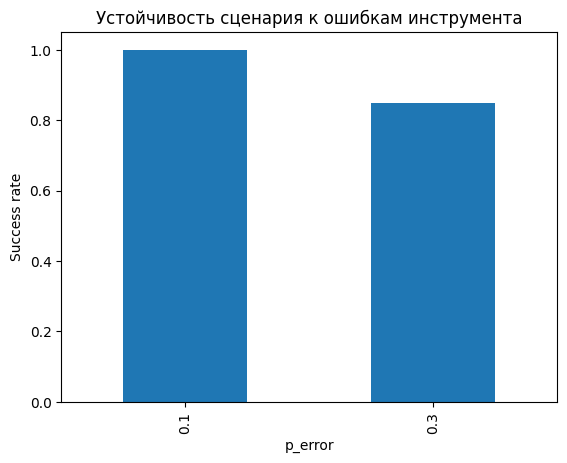

In [22]:
# Эта ячейка уже готова. Она не требует дописывания студентом.

if HAS_MATPLOTLIB:
    summary = pd.DataFrame({
        "p_error": [0.10, 0.30],
        "success_rate": [
            exp_10["successful"].mean(),
            exp_30["successful"].mean(),
        ],
        "mean_steps": [
            exp_10["steps"].mean(),
            exp_30["steps"].mean(),
        ],
    })

    display(summary)

    ax = summary.plot(
        x="p_error",
        y="success_rate",
        kind="bar",
        legend=False,
    )
    ax.set_ylabel("Success rate")
    ax.set_title("Устойчивость сценария к ошибкам инструмента")
    plt.show()

# 8. Идея семестрового проекта

Каждый проект в курсе должен содержать минимум:

1. явное состояние;
2. supervisor / cognitive / LLM level;
3. компонент теории автоматического управления;
4. интерфейс действия;
5. ограничения безопасности;
6. эксперимент и метрики.

In [23]:
project_idea = {
    "project_title": "",
    "application_domain": "",
    "supervisor_architecture": "",
    "control_component": "",
    "state_variables": [],
    "actions": [],
    "safety_constraints": [],
    "metrics": [],
    "expected_demo": "",
}

project_idea

{'project_title': '', 'application_domain': '', 'supervisor_architecture': '', 'control_component': '', 'state_variables': [], 'actions': [], 'safety_constraints': [], 'metrics': [], 'expected_demo': ''}

## Задание 11. Заполните `project_idea`

Примеры `application_domain`:

- UAV;
- ground robot;
- manipulator;
- data agent;
- multi-agent system.

Примеры `control_component`:

- PID;
- Kalman filter;
- LQR / LQG;
- MPC;
- CBF;
- RL + residual controller.

In [24]:
# ===== BEGIN STUDENT CODE =====

project_idea["project_title"] = "Агент-супервайзер для автоматических инженерных расчётов (МКЭ)"
project_idea["application_domain"] = "data agent: автоматизация инженерных расчётов (МКЭ)"
project_idea["supervisor_architecture"] = (
    "LangGraph (граф состояний). Сначала planner работает по правилам, "
    "потом можно взять LLM."
)
project_idea["control_component"] = (
    "PID (только P и I): регулятор меняет размер сетки, "
    "чтобы ошибка решения стала меньше заданной"
)
project_idea["state_variables"] = [
    "режим агента (Mode)",
    "цель и нужная точность",
    "текущая ошибка решения",
    "размер сетки",
    "время расчёта и число запусков",
    "error_count и last_error",
    "success_score",
]
project_idea["actions"] = [
    "run_solver",
    "refine_mesh",
    "coarsen_mesh",
    "request_observation",
    "write_file (только если есть permission_granted)",
    "no_op",
]
project_idea["safety_constraints"] = [
    "не больше 3 ошибок решателя, потом остановка",
    "лимит на число элементов сетки и на время расчёта",
    "нельзя писать в файлы модели без разрешения",
    "после 2 ошибок нельзя сразу запускать решатель снова",
]
project_idea["metrics"] = [
    "доля успешных запусков (success rate)",
    "среднее число шагов до цели",
    "число ошибок и доля времени в RECOVERY",
    "число нарушений ограничений",
    "разница между ошибкой решения и нужной точностью",
    "что будет, если вероятность ошибки растёт с 0.1 до 0.3",
]
project_idea["expected_demo"] = (
    "Серия из 50 запусков на модели решателя со случайными ошибками. "
    "Я сравню агента без регулятора и агента с PI-регулятором и safety filter. "
    "Покажу графики и один журнал запуска."
)

# ===== END STUDENT CODE =====

project_idea

{'project_title': 'Агент-супервайзер для автоматических инженерных расчётов (МКЭ)', 'application_domain': 'data agent: автоматизация инженерных расчётов (МКЭ)', 'supervisor_architecture': 'LangGraph (граф состояний). Сначала planner работает по правилам, потом можно взять LLM.', 'control_component': 'PID (только P и I): регулятор меняет размер сетки, чтобы ошибка решения стала меньше заданной', 'state_variables': ['режим агента (Mode)', 'цель и нужная точность', 'текущая ошибка решения', 'размер сетки', 'время расчёта и число запусков', 'error_count и last_error', 'success_score'], 'actions': ['run_solver', 'refine_mesh', 'coarsen_mesh', 'request_observation', 'write_file (только если есть permission_granted)', 'no_op'], 'safety_constraints': ['не больше 3 ошибок решателя, потом остановка', 'лимит на число элементов сетки и на время расчёта', 'нельзя писать в файлы модели без разрешения', 'после 2 ошибок нельзя сразу запускать решатель снова'], 'metrics': ['доля успешных запусков (succ

## Задание 12. Реализуйте валидатор идеи проекта

Добавляйте предупреждение, если:

- не указано название;
- не выбран supervisor;
- не выбран control component;
- нет переменных состояния;
- нет действий;
- нет safety constraints;
- нет метрик;
- нет описания демонстрации.

In [25]:
def validate_project_idea(
    idea: Dict[str, Any]
) -> List[str]:

    warnings: List[str] = []

    # ===== BEGIN STUDENT CODE =====

    if not (idea.get("project_title") or "").strip():
        warnings.append("Не указано название проекта")

    if not (idea.get("supervisor_architecture") or "").strip():
        warnings.append("Не выбран supervisor")

    if not (idea.get("control_component") or "").strip():
        warnings.append("Не выбран компонент ТАУ")

    if not idea.get("state_variables"):
        warnings.append("Нет переменных состояния")

    if not idea.get("actions"):
        warnings.append("Нет действий")

    if not idea.get("safety_constraints"):
        warnings.append("Нет ограничений безопасности")

    if not idea.get("metrics"):
        warnings.append("Нет метрик")

    if not (idea.get("expected_demo") or "").strip():
        warnings.append("Нет описания демонстрации")

    # ===== END STUDENT CODE =====

    return warnings

### Проверка идеи

In [26]:
warnings = validate_project_idea(project_idea)

if warnings:
    print("Нужно доработать:")
    for w in warnings:
        print("-", w)
else:
    print("Базовая структура проекта заполнена")

Базовая структура проекта заполнена


# 9. Контрольные вопросы

Ответьте в новой Markdown-ячейке.

1. Почему состояние агента желательно хранить явно, а не только внутри prompt?
2. Что является аналогом управляющего входа в LLM-agent системе?
3. Что является аналогом измерения?
4. Чем `PLAN` отличается от `ACT`?
5. Почему `RECOVERY` можно интерпретировать как элемент отказоустойчивого управления?
6. Зачем нужен safety filter, если planner считается «умным»?
7. Почему один успешный trace недостаточен для оценки архитектуры?
8. Какие метрики нужны для closed-loop agent system кроме accuracy?
9. Какую из рассмотренных архитектур вы бы выбрали для собственного проекта?
10. Какой компонент теории автоматического управления вы добавите в проект?

## Ответы на контрольные вопросы

**1. Почему состояние агента желательно хранить явно, а не только внутри prompt?**  
Явное состояние можно записать в журнал и проверить. Функцию перехода можно тестировать отдельно. У prompt есть предел длины, и в нём нет структуры. Модель может забыть или изменить часть информации. В ТАУ тоже нужен вектор состояния: без него систему нельзя наблюдать.

**2. Что является аналогом управляющего входа в LLM-agent системе?**  
Это действие агента, например вызов инструмента (`execute_tool`). Planner выбирает действие и отправляет его в среду, как регулятор отправляет сигнал на объект.

**3. Что является аналогом измерения?**  
Это наблюдение: ответ инструмента или API, то есть данные из среды. В коде это результат `perceive()` и результат `act()`.

**4. Чем `PLAN` отличается от `ACT`?**  
В `PLAN` агент только выбирает действие, среда не меняется. В `ACT` агент выполняет действие: среда меняется, и может быть ошибка. Между ними можно поставить safety filter.

**5. Почему `RECOVERY` можно интерпретировать как элемент отказоустойчивого управления?**  
В `RECOVERY` агент видит ошибку (`tool_error`), считает её (`error_count`) и пробует ещё раз через `PLAN`. Если ошибок три, он останавливается. Так работает отказоустойчивое управление: после сбоя система продолжает работать или безопасно останавливается.

**6. Зачем нужен safety filter, если planner считается «умным»?**  
Planner может ошибиться, особенно если это LLM. Safety filter — это отдельная проверка по простым правилам. Она работает всегда, даже если план плохой. Это как предохранительный клапан: он не зависит от регулятора.

**7. Почему один успешный trace недостаточен для оценки архитектуры?**  
В среде есть случайные ошибки, поэтому один запуск — это один случайный результат. Он может быть удачным случайно. Нужно много запусков, чтобы увидеть средний результат и разброс.

**8. Какие метрики нужны для closed-loop agent system кроме accuracy?**  
Нужны: доля успешных запусков, число шагов до цели, число ошибок, доля времени в `RECOVERY`, число нарушений правил безопасности, время и стоимость запуска. Ещё нужно смотреть, что будет, если ошибок становится больше.

**9. Какую из рассмотренных архитектур вы бы выбрали для собственного проекта?**  
Я выбрал бы LangGraph. В нём состояние хранится в графе, и это похоже на формулу q_{t+1} = F(q_t, o_t). Риск низкий, он написан на Python. Легко добавить safety filter и журнал. Потом planner можно заменить на LLM.

**10. Какой компонент теории автоматического управления вы добавите в проект?**  
Я добавлю PI-регулятор. Цель — нужная точность расчёта. Регулятор меняет размер сетки, если ошибка слишком большая. Сверху будет safety filter с ограничениями.

# 10. Критерии завершения семинара

К концу 90 минут у вас должны быть:

| Компонент | Минимальный результат |
|---|---|
| Таблица архитектур | заполнены инженерные критерии для всех строк |
| Конечный автомат | реализована `transition()` |
| Когнитивные функции | работают `perceive`, `plan`, `act`, `evaluate` |
| Agent loop | `run_agent()` возвращает журнал |
| Метрики | реализована `compute_metrics()` |
| Safety | реализован `safety_filter()` |
| Эксперимент | `batch_experiment()` сравнивает серию запусков |
| Проект | заполнена `project_idea` и работает валидатор |

## Что сдавать

Сохраните заполненный ноутбук в формате:

`Surname_Name_Seminar_01.ipynb`

Перед сдачей:

1. выполните `Kernel -> Restart & Run All`;
2. убедитесь, что нет необъяснённых ошибок;
3. оставьте видимыми результаты тестов и экспериментов;
4. не удаляйте исходные markdown-ячейки и границы `BEGIN/END STUDENT CODE`.